Columns in dataset: ['student_id', 'gender', 'age_group', 'prefers_tea', 'tea_type', 'snack_choice', 'cups_per_day']

First 5 rows:


,student_id,gender,age_group,prefers_tea,tea_type,snack_choice,cups_per_day
0,S001,Male,21-23,No,Black,Samosa,2
1,S002,Male,21-23,No,Green,Samosa,3
2,S003,Male,18-20,No,Doodh Patti,Biscuit,0
3,S004,Male,21-23,Yes,NaN,Samosa,1
4,S005,Male,18-20,Yes,Green,Samosa,4



Q1: Most Preferred Tea Type
prefers_tea
Yes    51
No     49
Name: count, dtype: int64
--> Most preferred tea type (among tea drinkers): Yes

Q2: Average Number of Cups per Gender
gender
Female    2.6
Male      3.0
Name: cups_per_day, dtype: float64

Q3: Bar Chart of Snack Choices
snack_choice
Samosa     40
Chips      31
Biscuit    29
Name: count, dtype: int64


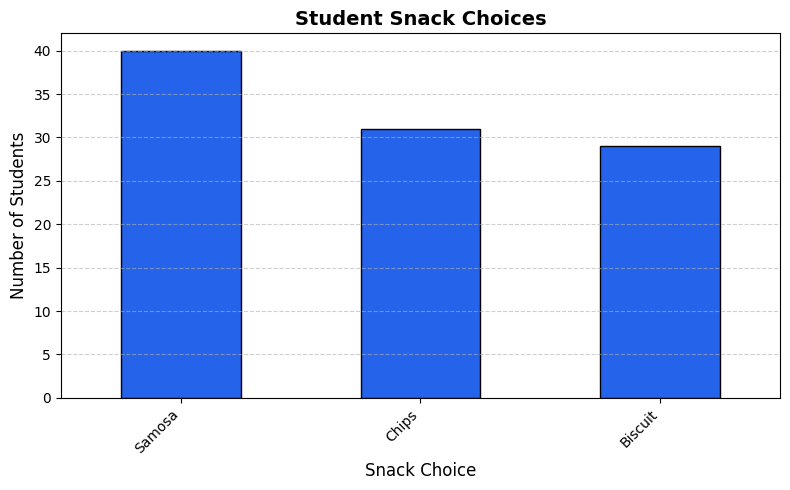


Q4: Tea Preference by Age Group
prefers_tea  No  Yes
age_group           
18-20        19   20
21-23        17   15
24-26        13   16


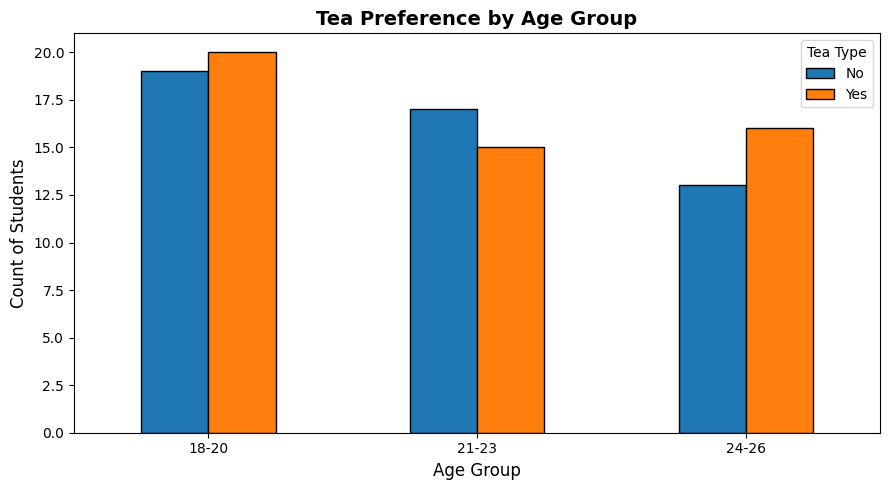


Q5: Students Who Don't Drink Tea
--> Total number of students who don't drink tea: 54


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset (Update filename if yours is named 'student_tea_snacks (1).csv')
filename = 'student_tea_snacks.csv'
df = pd.read_csv(filename)

# Clean column names (strip extra spaces) and inspect columns
df.columns = df.columns.str.strip()
print("Columns in dataset:", df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())

# Automatically identify relevant columns based on keywords
tea_col = [c for c in df.columns if 'tea' in c.lower()][0]
cups_col = [c for c in df.columns if 'cup' in c.lower()][0]
gender_col = [c for c in df.columns if 'gender' in c.lower()][0]
snack_col = [c for c in df.columns if 'snack' in c.lower()][0]
age_col = [c for c in df.columns if 'age' in c.lower()][0]

print("\n" + "="*50)
# Q1: What is the most preferred tea type?
print("Q1: Most Preferred Tea Type")
tea_counts = df[tea_col].value_counts()
print(tea_counts)
# Exclude non-drinkers if 'None' or 'No' is the top category when finding preferred tea
drinkers_only = df[~df[tea_col].astype(str).str.lower().isin(['none', 'no', 'nan', "don't drink", 'do not drink'])]
most_preferred = drinkers_only[tea_col].value_counts().idxmax()
print(f"--> Most preferred tea type (among tea drinkers): {most_preferred}")

print("\n" + "="*50)
# Q2: What is the average number of cups per gender?
print("Q2: Average Number of Cups per Gender")
df[cups_col] = pd.to_numeric(df[cups_col], errors='coerce')
avg_cups_gender = df.groupby(gender_col)[cups_col].mean().round(2)
print(avg_cups_gender)

print("\n" + "="*50)
# Q3: Make a bar chart of snack choices.
print("Q3: Bar Chart of Snack Choices")
snack_counts = df[snack_col].value_counts()
print(snack_counts)

plt.figure(figsize=(8, 5))
snack_counts.plot(kind='bar', color='#2563eb', edgecolor='black')
plt.title('Student Snack Choices', fontsize=14, fontweight='bold')
plt.xlabel('Snack Choice', fontsize=12)
plt.ylabel('Number of Students', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print("\n" + "="*50)
# Q4: Compare tea preference by age group.
print("Q4: Tea Preference by Age Group")
tea_by_age = pd.crosstab(df[age_col], df[tea_col])
print(tea_by_age)

# Optional grouped bar visual for Q4
tea_by_age.plot(kind='bar', figsize=(9, 5), edgecolor='black')
plt.title('Tea Preference by Age Group', fontsize=14, fontweight='bold')
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Count of Students', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Tea Type')
plt.tight_layout()
plt.show()

print("\n" + "="*50)
# Q5: Count the number of students who don't drink tea.
print("Q5: Students Who Don't Drink Tea")
non_drinkers = df[
    df[tea_col].isna() |
    df[tea_col].astype(str).str.strip().str.lower().isin(['none', 'no', "don't drink", 'do not drink', 'never', '0']) |
    (df[cups_col] == 0)
]
print(f"--> Total number of students who don't drink tea: {len(non_drinkers)}")